# Verarbeitung und Darstellung der Messdaten


## Import all libraries and load data as pandas dataframe


In [76]:
#import libraries
import pandas as pd
import numpy as np
import scipy.signal as sci
import matplotlib.pyplot as plot

<Axes: title={'center': 'Accelerometer Test'}, xlabel='Time in s', ylabel='Acceleration in g'>

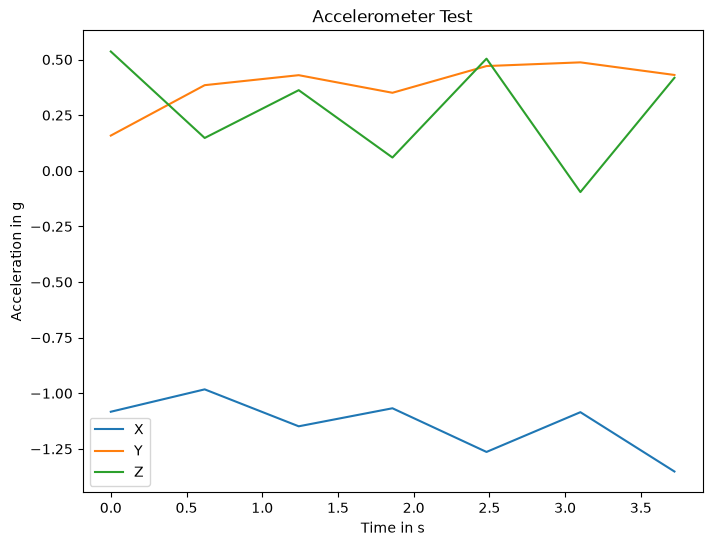

In [77]:
#import recorded .csv Files and store them in a dataframe
df = pd.read_csv(r"C:\Users\lucie\Documents\Biosignalverarbeitung\Lab1\source\hochrunter.csv", sep="\t", header=None, names=['X', 'Y', 'Z', 'Time'])

#convert time from ms into s
df['Time'] = (df['Time'] - df['Time'].iloc[0]) / 1000
df['X'] = df['X'] / 1024
df['Y'] = df['Y'] / 1024
df['Z'] = df['Z'] / 1024
df_4s = df[df['Time'] <= 4]

# display data
df_4s.plot(x = 'Time', y = ['X', 'Y', 'Z'], ylabel='Acceleration in g', 
        xlabel='Time in s', figsize= [8, 6], title="Accelerometer Test")

<Axes: title={'center': 'Accelerometer Test'}, xlabel='Time in s', ylabel='Acceleration in g'>

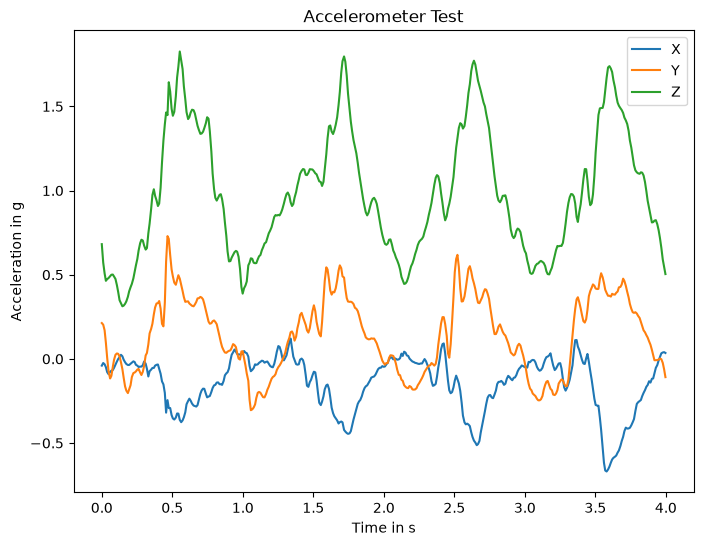

In [86]:
#import recorded .csv Files and store them in a dataframe
df = pd.read_csv(r"C:\Users\lucie\Documents\Biosignalverarbeitung\Lab1\source\hochrunter_2.csv", sep="\t", header=None, names=['X', 'Y', 'Z', 'Time'])

#convert time from ms into s
df['Time'] = (df['Time'] - df['Time'].iloc[0]) / 1000

df['X'] = df['X'] / 1024
df['Y'] = df['Y'] / 1024
df['Z'] = df['Z'] / 1024

df_4s = df[df['Time'] <= 4]

# display data
df_4s.plot(x = 'Time', y = ['X', 'Y', 'Z'], ylabel='Acceleration in g', 
        xlabel='Time in s', figsize= [8, 6], title="Accelerometer Test")

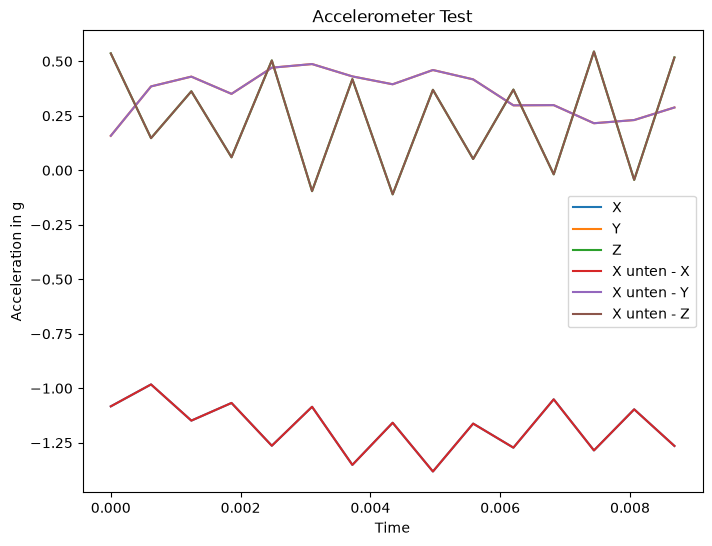

In [87]:
#import recorded .csv Files and store them in a dataframe
df = pd.read_csv(r"C:\Users\lucie\Documents\Biosignalverarbeitung\Lab1\source\achsen.csv", sep="\t", header=None, names=['X', 'Y', 'Z', 'Time'])


#convert time from microseconds into s

df['Time'] = (df['Time'] - df['Time'].iloc[0]) / 1000000

df['X'] = df['X'] / 1024
df['Y'] = df['Y'] / 1024
df['Z'] = df['Z'] / 1024

# display data
ax = df.plot(x='Time', y=['X', 'Y', 'Z'], ylabel='Acceleration in g',
              xlabel='Time in s', figsize=[8, 6], title="Accelerometer Test")

for df, name in zip([df],
                    ['X unten', 'Y oben', 'Y unten', 'Z oben', 'Z unten']):
    for axis in ['X', 'Y', 'Z']:
        df.plot(x='Time', y=axis, ax=ax, label=f'{name} - {axis}')

#df.plot(x = 'Time', y = ['X', 'Y', 'Z'], ylabel='Acceleration in g', 
      #  xlabel='Time in s', figsize= [8, 6], title="Accelerometer Test")

Mittlerer Zeitabstand: 620.29 ms
Mittlere Abtastfrequenz: 1.61 Hz
Standardabweichung der Zeitabstände: 0.61 ms


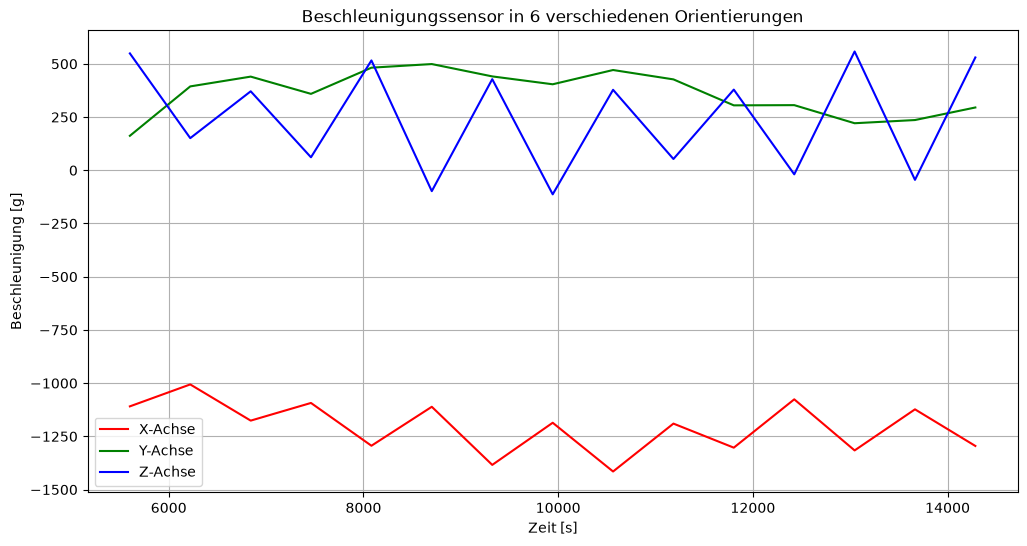

In [92]:
# 1. Datei einlesen (Dateinamen ggf. anpassen)
#df = pd.read_csv('achsen.csv', sep='\t', header=None, names=['Zeit_ms', 'X', 'Y', 'Z'])
df = pd.read_csv(r"C:\Users\lucie\Documents\Biosignalverarbeitung\Lab1\source\achsen.csv", sep="\t", header=None, names=['X', 'Y', 'Z', 'Time'])

# --- BERECHNUNG DER ABTASTFREQUENZ ---
# Zeitdifferenzen zwischen aufeinanderfolgenden Messungen berechnen
dt = df['Time'].diff().dropna()

# Mittlerer Zeitabstand in Millisekunden und Sekunden
dt_mean_ms = dt.mean()
mittlere_frequenz = 1000.0 / dt_mean_ms
std_abweichung = dt.std()

print(f"Mittlerer Zeitabstand: {dt_mean_ms:.2f} ms")
print(f"Mittlere Abtastfrequenz: {mittlere_frequenz:.2f} Hz")
print(f"Standardabweichung der Zeitabstände: {std_abweichung:.2f} ms")


# --- PLOTTEN DER 6 ORIENTIERUNGEN ---
# (Falls Sie die Datei gewechselt haben, hier den Namen der Orientierungs-Datei eintragen)
#df_orient = pd.read_csv('orientierungen_daten.txt', sep='\t', header=None, names=['Zeit_ms', 'X', 'Y', 'Z'])
#df_orient['Zeit_s'] = (df_orient['Zeit_ms'] - df_orient['Zeit_ms'].iloc[0]) / 1000.0

plt.figure(figsize=(12, 6))
plt.plot(df['Time'], df['X'], label='X-Achse', color='red')
plt.plot(df['Time'], df['Y'], label='Y-Achse', color='green')
plt.plot(df['Time'], df['Z'], label='Z-Achse', color='blue')

plt.xlabel('Zeit [s]')
plt.ylabel('Beschleunigung [g]')
plt.title('Beschleunigungssensor in 6 verschiedenen Orientierungen')
plt.legend()
plt.grid(True)
plt.show()


In [75]:
#import recorded .csv Files and store them in a dataframe
df1 = pd.read_csv(r"C:\Users\lucie\Documents\Biosignalverarbeitung\Lab1\source\x_oben.csv", sep="\t")
df2 = pd.read_csv(r"C:\Users\lucie\Documents\Biosignalverarbeitung\Lab1\source\x_unten.csv", sep="\t")
df3 = pd.read_csv(r"C:\Users\lucie\Documents\Biosignalverarbeitung\Lab1\source\y_oben.csv", sep="\t")
df4 = pd.read_csv(r"C:\Users\lucie\Documents\Biosignalverarbeitung\Lab1\source\y_unten.csv", sep="\t")
df5 = pd.read_csv(r"C:\Users\lucie\Documents\Biosignalverarbeitung\Lab1\source\z_oben.csv", sep="\t")
df6 = pd.read_csv(r"C:\Users\lucie\Documents\Biosignalverarbeitung\Lab1\source\z_unten.csv", sep="\t")

#convert time from microseconds into s
for df in [df1, df2, df3, df4, df5, df6]:
    df['Time'] = (df['Time'] - df['Time'].iloc[0]) / 1000

# display data
ax = df1.plot(x='Time', y=['X', 'Y', 'Z'], ylabel='Acceleration in g',
              xlabel='Time in s', figsize=[8, 6], title="Accelerometer Test")

for df, name in zip([df2, df3, df4, df5, df6],
                    ['X unten', 'Y oben', 'Y unten', 'Z oben', 'Z unten']):
    for axis in ['X', 'Y', 'Z']:
        df.plot(x='Time', y=axis, ax=ax, label=f'{name} - {axis}')

KeyError: 'Time'

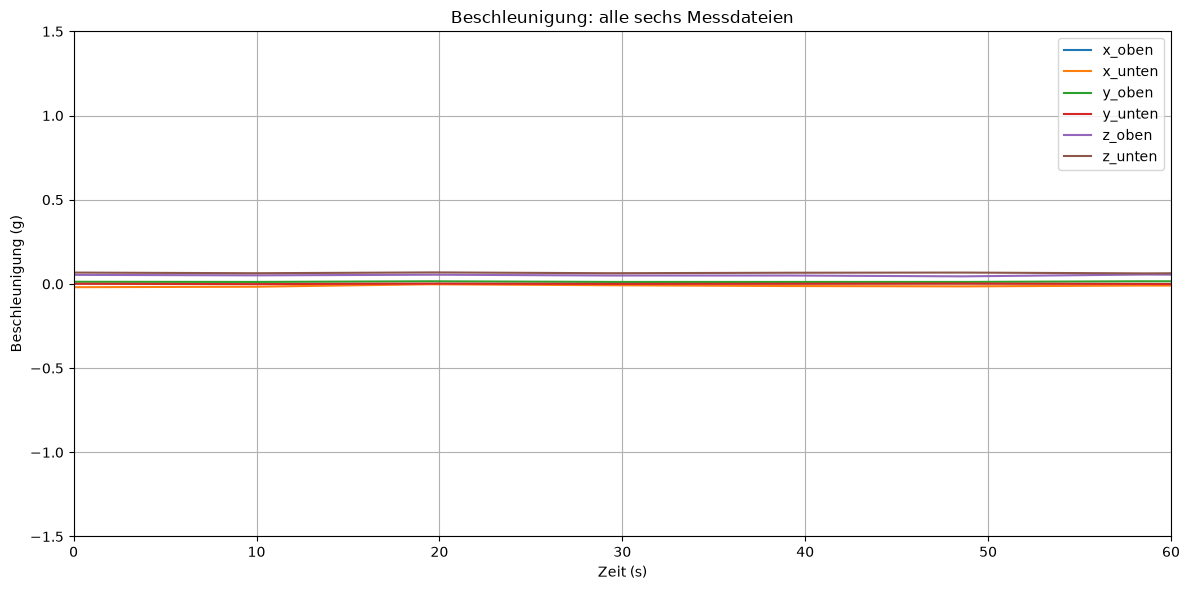

In [73]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ordner = Path(r"C:\Users\lucie\Documents\Biosignalverarbeitung\Lab1\source")

dateien = [
    ("x_oben", "X"),
    ("x_unten", "X"),
    ("y_oben", "Y"),
    ("y_unten", "Y"),
    ("z_oben", "Z"),
    ("z_unten", "Z"),
]

fig, ax = plt.subplots(figsize=(12, 6))

for dateiname, signal in dateien:
    pfad = ordner / f"{dateiname}.csv"
    df = pd.read_csv(
        pfad,
        sep="\t",
        header=None,
        names=["X", "Y", "Z", "Time"]
    )

    zeit = pd.to_numeric(df["Time"], errors="raise")
    zeit = (zeit - zeit.iloc[0]) / 1000  # Millisekunden ab Start -> Sekunden

    beschleunigung = pd.to_numeric(df[signal], errors="coerce") / 1024
    ax.plot(zeit, beschleunigung, label=dateiname)

ax.set_xlim(0, 60)
ax.set_ylim(-1.5, 1.5)
ax.set_xlabel("Zeit (s)")
ax.set_ylabel("Beschleunigung (g)")
ax.set_title("Beschleunigung: alle sechs Messdateien")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

# Filter acceleration data applying different filter techniques
## Bandpass filter (Butterworth 4. order)

Wir möchten einen Filter verwende, der das Signal nicht verschiebt, demnach einen zero-Phase Filter. Scipy bietet diese Option mit der _filtfilt()_ Methode an. Dieser verwendet zwei _Infinite Impuls Response_ Filter hintereinander geschaltet, jedoch wird der erste vorwärts und der zweite rückwärts angewandt, um keine Phasenverschiebung zu erhalten.

Dies ist auch in folgender Abbildung zu erkennen. Die gestrichelte rote Line stellt einen Filter dar, welcher das Signal filtert und störende Frequenzen entfernt, jedoch ist dieser um eine Phase verschoben zum eigentlichen Signal. Die rote Line ist die zweite Anwendung des Filters. Würde man den zweiten Filter jedoch rückwärts anwenden, würde man die schwarze Linie und somit das Ergebnis der _filtfilt()_ methode erhalten.



![Unterschied zwischen verschiedenen Filtertypen](bilder/zeroPhase.png)

In [ ]:
# Setting up a butterworth filter 

def butter_bandpass(lowcut,fs,order):
    
    # nyq: Nyquist Theorem
    nyq = 0.5 * fs
    # low is calculated in relation to cutoff frequency and sampling frequency
    low = lowcut / nyq
    
    order = 4
    
    b, a = sci.butter(order, [low], 'lowpass', analog=False)
    
    return b, a



In [ ]:
def butter_bandpass_filter(signal, lowcut, fs, order):
    #use filtfilt for a zero-phase filtering
    b, a = butter_bandpass(lowcut,fs, order)
    y = sci.filtfilt(b, a, signal, axis = 0, order=order)
    return y